# Text Clustering as Classification with LLMs: Baseline (Qwen via Ollama)
Runs the original pipeline step by step. Each step is its own cell, so you can rerun one step without redoing the others.

**Steps:** 0 Setup → 1 Select example labels → 2 Generate labels → 3 Classify texts → 4 Evaluate → 5 Save and inspect results

Before running: Ollama must be open, and `qwen2.5:7b` must be pulled.

In [10]:
import os, sys
# Run from the main project folder even though the notebook is in /notebooks
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

## 0. Setup and settings
Change `DATA` to run another dataset.

In [11]:
import os, json, time, math, sys, urllib.request
import pandas as pd

DATA = "massive_scenario"      # dataset folder name inside ./dataset
MODEL = "qwen2.5:7b"           # Ollama model
SIZE = "small"                 # the paper uses the small split
OUT = "./generated_labels"
os.makedirs(OUT, exist_ok=True)
os.makedirs("./results", exist_ok=True)
print("Working folder:", os.getcwd())

Working folder: c:\Users\itsfr\Desktop\Master\Text-Clustering-via-LLM-main


In [12]:
# Check that the dataset exists and Ollama is running with the model
data_file = f"./dataset/{DATA}/{SIZE}.jsonl"
assert os.path.exists(data_file), f"Dataset not found: {data_file}"
with open(data_file, encoding="utf-8") as f:
    n_texts = sum(1 for _ in f)
print(f"{DATA}: {n_texts} texts")

try:
    tags = json.load(urllib.request.urlopen("http://localhost:11434/api/tags", timeout=5))
    models = [m["name"] for m in tags["models"]]
    print("Ollama is running. Models:", models)
    assert any(m.startswith(MODEL) for m in models), f"Run: ollama pull {MODEL}"
except Exception as e:
    print("Ollama problem:", e)

massive_scenario: 2974 texts
Ollama is running. Models: ['qwen2.5:7b']


## 1. Select example labels (20% of the true labels)
Only needs to run once. The seed is fixed, so it picks the same labels every time.

In [13]:
!python select_part_labels.py
with open(f"{OUT}/chosen_labels.json", encoding="utf-8") as f:
    chosen = json.load(f)
print("Example labels given to the LLM:", chosen[DATA])

Use dataset ./dataset/arxiv_fine\small.jsonl
Length of dataset: 3674
93
Choose num: 18
Use dataset ./dataset/banking77\small.jsonl
Length of dataset: 3080
77
Choose num: 15
Use dataset ./dataset/clinc\small.jsonl
Length of dataset: 4500
150
Choose num: 30
Use dataset ./dataset/clinc_domain\small.jsonl
Length of dataset: 4500
10
Choose num: 2
Use dataset ./dataset/few_event\small.jsonl
Length of dataset: 4742
34
Choose num: 6
Use dataset ./dataset/few_nerd_nat\small.jsonl
Length of dataset: 3789
58
Choose num: 11
Use dataset ./dataset/few_rel_nat\small.jsonl
Length of dataset: 4480
64
Choose num: 12
Use dataset ./dataset/go_emotion\small.jsonl
Length of dataset: 5940
27
Choose num: 5
Use dataset ./dataset/massive_intent\small.jsonl
Length of dataset: 2974
59
Choose num: 11
Use dataset ./dataset/massive_scenario\small.jsonl
Length of dataset: 2974
18
Choose num: 3
Use dataset ./dataset/mtop_domain\small.jsonl
Length of dataset: 4386
11
Choose num: 2
Use dataset ./dataset/mtop_intent\smal

## 2. Generate labels with the LLM
About `texts / 15` LLM calls plus one merge call. This takes a few minutes.

In [14]:
t0 = time.time()
!python label_generation.py --data {DATA} --model {MODEL}
time_labelgen = time.time() - t0
print(f"Label generation time: {time_labelgen/60:.1f} min")

Model: qwen2.5:7b at http://localhost:11434/v1
use_large:  False
Use dataset ./dataset/massive_scenario\small.jsonl
Length of dataset: 2974
Total cluster num: 18
JSON file './generated_labels\massive_scenario_small_true_labels.json' written.
['alarm', 'audio', 'calendar', 'cooking', 'datetime', 'email', 'general', 'iot', 'lists', 'music', 'news', 'play', 'qa', 'recommendation', 'social', 'takeaway', 'transport', 'weather']
Total labels given by LLM: 74
['transport', 'datetime', 'play', 'communication', 'query_information', 'reminder', 'weather', 'schedule', 'query_info', 'personal_request', 'sports', 'travel', 'location', 'request', 'other', 'email', 'cancel', 'personal_care', 'navigation', 'alarm', 'query', 'time_query', 'entertainment', 'time', 'audio', 'customer_service', 'appointment', 'informational', 'household', 'productivity', 'politics', 'play_music', 'search', 'finance', 'alarms', 'news', 'event_date', 'miscellaneous', 'social_media', 'information_request', 'contact', 'audio_

In [15]:
# Inspect: true labels vs LLM labels
def load(name):
    with open(f"{OUT}/{DATA}_{SIZE}_{name}.json", encoding="utf-8") as f:
        return json.load(f)
true_labels = load("true_labels")
before = load("llm_generated_labels_before_merge")
after = load("llm_generated_labels_after_merge")
print(f"True clusters: {len(true_labels)} | LLM labels before merge: {len(before)} | after merge: {len(after)}")
print("\nLLM labels after merge:\n", sorted(after))

True clusters: 18 | LLM labels before merge: 74 | after merge: 71

LLM labels after merge:
 ['alarm', 'alarms_reminders', 'alarms_reminders_time', 'alert_request', 'appointment', 'audio', 'audio_control', 'audio_play', 'birthday', 'calendar', 'cancel', 'coffee_request', 'communication', 'complaints', 'contact', 'credit', 'crime', 'customer_service', 'date', 'datetime', 'datetime_request', 'definition', 'email', 'entertainment', 'event', 'event_date', 'events', 'finance', 'household', 'information_request', 'informational', 'legal_consultations', 'location', 'media', 'media_playback', 'miscellaneous', 'music', 'navigation', 'news', 'notification', 'other', 'personal_care', 'personal_music', 'personal_request', 'planning', 'play', 'play_game', 'play_music', 'policy', 'politics', 'productivity', 'query', 'query_information', 'radio', 'reminder', 'request', 'request_action', 'request_info', 'request_service', 'schedule', 'search', 'shopping', 'social_media', 'sports', 'technology', 'time',

## 2b. Debug the merge step
The merge step returned the same 76 labels it received, so nothing was merged.
This cell reruns only the merge and prints Qwen's raw answer, to see whether the problem is invalid JSON or a weak merge.

In [16]:
import importlib, label_generation as lg
from types import SimpleNamespace
importlib.reload(lg)
lg.MODEL = MODEL
client = lg.ini_client(SimpleNamespace(base_url="http://localhost:11434/v1", api_key="ollama"))

prompt = lg.prompt_construct_merge_label(before)
raw = lg.chat(prompt, client)
print("RAW ANSWER:\n", raw)
try:
    parsed = lg.parse_json(raw)
    merged = [l for v in parsed.values() for l in (v if isinstance(v, list) else [v])]
    print(f"\nParsed OK: {len(merged)} labels")
    print(sorted(merged))
except Exception as e:
    print("\nCould not parse:", e)

RAW ANSWER:
 {
  "merged_labels": [
    "transport",
    "datetime",
    "play",
    "communication",
    "query_information",
    "reminder",
    "weather",
    "schedule",
    "personal_request",
    "sports",
    "travel",
    "location",
    "request",
    "other",
    "email",
    "cancel",
    "personal_care",
    "navigation",
    "alarm",
    "query",
    "time_query",
    "entertainment",
    "time",
    "audio",
    "customer_service",
    "appointment",
    "informational",
    "household",
    "productivity",
    "politics",
    "play_music",
    "search",
    "finance",
    "news",
    "event_date",
    "miscellaneous",
    "social_media",
    "information_request",
    "contact",
    "audio_play",
    "events",
    "media",
    "upcoming_events",
    "event",
    "request_action",
    "planning",
    "request_service",
    "notification",
    "calendar",
    "play_game",
    "media_playback",
    "coffee_request",
    "legal_consultations",
    "audio_control",
    "datet

## 2c. Save the merged labels
Qwen's merge is valid JSON but weak (76 → 71 labels). We keep it as the honest baseline and save it as the label list used in Step 3.

In [18]:
with open(f"{OUT}/{DATA}_{SIZE}_llm_generated_labels_after_merge.json", "w", encoding="utf-8") as f:
    json.dump(merged, f, indent=2, ensure_ascii=False)
after = merged
print(f"Saved {len(after)} labels for classification")

Saved 71 labels for classification


## 3. Classify every text into one label
This is the slow step: one LLM call per text. Progress is printed every 200 texts.

In [19]:
t0 = time.time()
!python given_label_classification.py --data {DATA} --model {MODEL}
time_classify = time.time() - t0
print(f"Classification time: {time_classify/60:.1f} min")

Model: qwen2.5:7b at http://localhost:11434/v1
False
Use dataset ./dataset/massive_scenario\small.jsonl
Length of dataset: 2974
Length of label list: 76
Total sample number: 0	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 200	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 400	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 600	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 800	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 1000	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 1200	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total sample number: 1400	JSON file './generated_labels\massive_scenario_small_find_labels.json' written.
Total 

## 4. Evaluate (ACC, NMI, ARI)

In [20]:
import importlib, evaluate as ev
importlib.reload(ev)
gold = ev.load_data("./dataset/", DATA, SIZE == "large")
with open(f"{OUT}/{DATA}_{SIZE}_find_labels.json", encoding="utf-8") as f:
    pred_dict = json.load(f)
y_true_raw = ev.get_labels(gold)
y_pred_raw = ev.get_predict_labels(gold, pred_dict)
y_true_raw = y_true_raw[:len(y_pred_raw)]
y_true, k_true = ev.convert_label_to_ids(y_true_raw)
y_pred, k_pred = ev.convert_label_to_ids(y_pred_raw)
scores = {k: round(float(v), 4) for k, v in ev.clustering_score(y_true, y_pred).items()}
unsuccessful = len(pred_dict.get("Unsuccessful", []))
print(scores)
print(f"Texts the LLM could not classify: {unsuccessful}")

Length of labels: 2974
Number of Clusters: 18
Length of labels: 2974
Number of Clusters: 71
{'ACC': 0.3988, 'ARI': 0.3203, 'NMI': 0.5583}
Texts the LLM could not classify: 175


## 5. Save results
Each run is added as a new row to `results/results.csv`, so you can compare baseline vs improved runs later.

In [21]:
llm_calls = math.ceil(n_texts / 15) + 1 + n_texts   # label generation + merge + classification
row = {
    "method": "baseline", "dataset": DATA, "model": MODEL, "n_texts": n_texts,
    "true_clusters": k_true, "predicted_clusters": k_pred,
    **scores, "unsuccessful": unsuccessful, "llm_calls": llm_calls,
    "time_min": round((globals().get("time_labelgen", 0) + globals().get("time_classify", 0)) / 60, 1),
    "date": time.strftime("%Y-%m-%d %H:%M"),
}
path = "./results/results.csv"
df = pd.read_csv(path) if os.path.exists(path) else pd.DataFrame()
df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
df.to_csv(path, index=False)
df

,method,dataset,model,n_texts,true_clusters,predicted_clusters,ACC,ARI,NMI,unsuccessful,llm_calls,time_min,date
0,baseline,massive_scenario,qwen2.5:7b,2974,18,71,0.3988,0.3203,0.5583,175,3174,25.9,2026-11-07 14:03


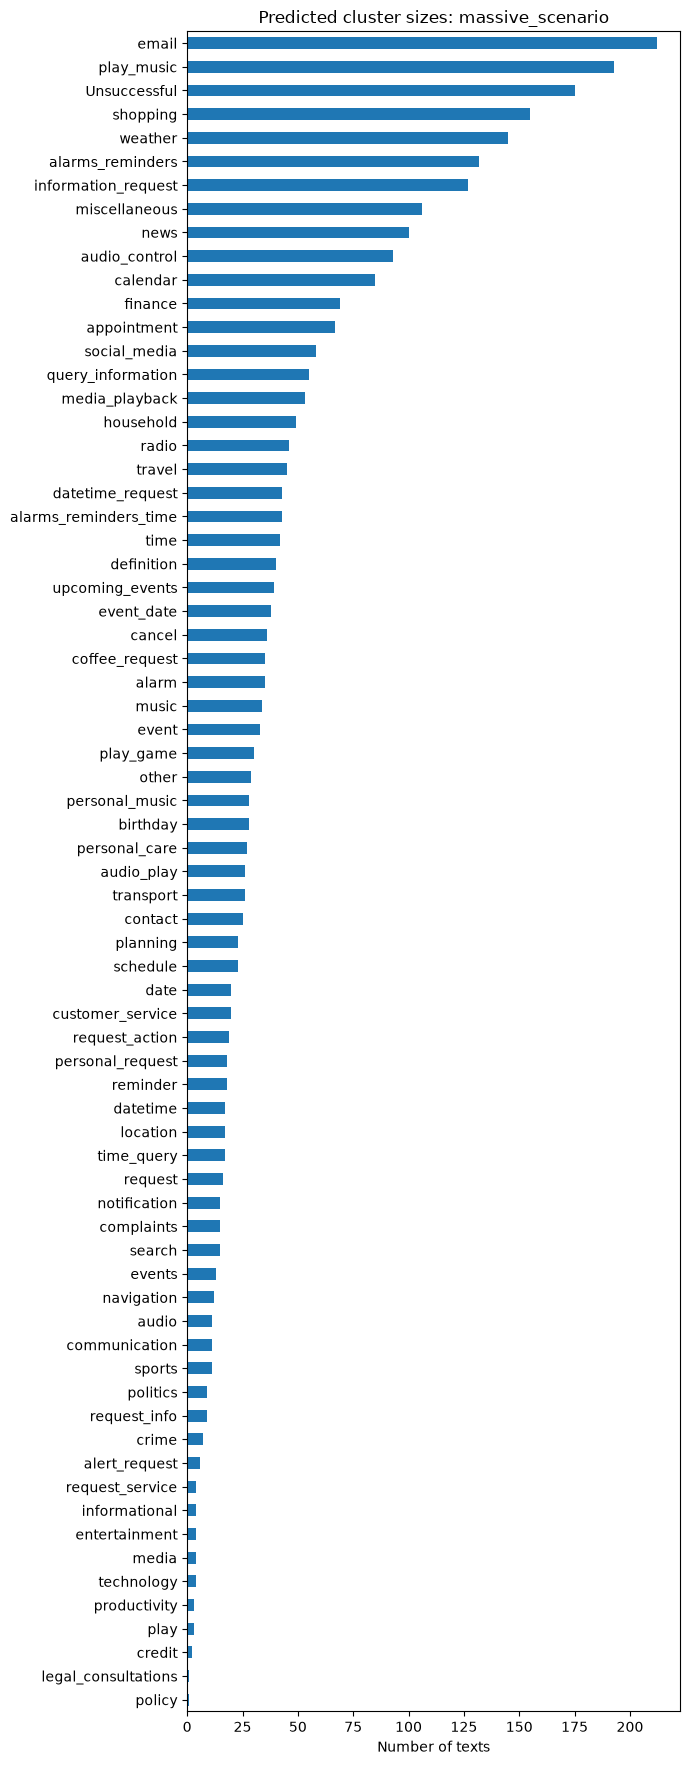

In [22]:
# Cluster sizes predicted by the LLM
import matplotlib.pyplot as plt
sizes = {k: len(v) for k, v in pred_dict.items() if v}
pd.Series(sizes).sort_values().plot.barh(figsize=(7, max(3, len(sizes) * 0.25)))
plt.title(f"Predicted cluster sizes: {DATA}")
plt.xlabel("Number of texts"); plt.tight_layout(); plt.show()